In [1]:
## Packages Import
import copy
import numpy             as np
import matplotlib.pyplot as plt

In [2]:
class VLMPanel:
    """
    Vortex Lattice Method panel object with ring vortex
    """
    #--------------------#
    #   Initialization   #
    #--------------------#
    def __init__(self, p, b, s_type):
        """
        Panel is of quadrilateral shape and vertices must be ordered from root
        position on leading-edge proceeding in counterclockwise direction.
        Ring vortex is placed on top of the panel; horseshoe vortex is approximated
        by a ring vortex whose starting vortex extends far back.
        """
        # Wing geometry
        self.span = b       # wing span [m]

        # Panel geometry
        self.pnt    = p        # panel vertices
        self.ctr    = None     # control point
        self.normal = None     # normal direction
        self.chord  = None     # chord length [m]
        self.width  = None     # pannel width [m]
        self.area   = None     # panel area   [m**2]

        # Vortex parameters
        self.sing = s_type      # type of singularity element
        self.vrt  = None        # ring vortex points
        
        self._get_panel_geom()
        self._get_vortex_geom(20*b)


    #-------------#
    #   Methods   #
    #-------------#
    def _get_panel_geom(self):
        """
        Compute panel geometric parameters such as control point position, normal
        versor, chord length, width and area, starting from panel's vertices.
        """
        p = self.pnt

        # Compute representative panel's geometric parameters
        c_avg = 0.5 * (np.linalg.norm(p[2] - p[1]) + np.linalg.norm(p[3] - p[0]))  # average chord length
        w_avg = 0.5 * (np.linalg.norm(p[2] - p[3]) + np.linalg.norm(p[1] - p[0]))  # average width

        # Compute position of control point
        cp = (p[0] + p[1] + 3*p[3] + 3*p[2]) / 8    # three-quarter line

        # Compute normal versor and panel surface
        ai = np.zeros(3)
        for i, pi in enumerate(p):
            qi = p[(i + 1) % len(p)]
            ai += np.cross(pi, qi)

        av = 0.5 * ai
        a = np.linalg.norm(av)
        if a > 0.0:
            n = av / a
        else:
            # Degenerate cells with zero area
            print(f"Degenerate panel {i} with {len(p)} vertices")

        self.ctr    = cp
        self.normal = n
        self.chord  = c_avg
        self.width  = w_avg
        self.area   = a

    def _get_vortex_geom(self, d):
        """ 
        Compute ring vortex's vertices position starting from panel's vertices: the
        leading segment is placed on the panel's quarter chord line. Horseshoe vortex
        is approximated by a ring vortex with negligible contribution by the wake
        vortex.

        Input:
        d -> wake vortex distance from wing
        """
        p = self.pnt

        v = []
        for i, pi in enumerate(p):
            vi = np.copy(pi)

            if self.sing == "horseshoe":
                # Horseshoe vortex approximation
                if i in [2, 3]:
                    # Wake vortex lies far behind the wing
                    vi[0] += d   # HP: trailing vortices parallel to x-axis
                    v.append(vi)
                    continue

            # Compute offset based on position of point
            if i in [0, 3]:
                offset = 0.25 * (p[3] - p[0])   # panel's root
            elif i in [1, 2]:
                offset = 0.25 * (p[2] - p[1])   # panel's tip
            # Apply offset to panel's vertices
            vi += offset
            v.append(vi)

        self.vrt = v

In [ ]:
class VLMGrid:
    """
    Vortex Lattice Method grid object
    """
    #--------------------#
    #   Initialization   #
    #--------------------#
    def __init__(self, b, c, theta, gamma, lamb, sym,
                s_type, u_inf, n):
        """
        Wing is discretized into a number of panel elements both in spanwise and
        chordwise direction.
        """
        # Wing geometry
        self.span     = b       # wing span                 [m]
        self.chord    = c       # chord lengths             [m]
        self.incid    = theta   # angle of incidence        [rad]
        self.dihedron = gamma   # dihedral angle            [rad]
        self.sweep    = lamb    # quarter-chord sweep angle [rad]
        self.symmetric = sym    # symmetric wing

        # Vortex parameters
        self.sing = s_type      # type of singularity element

        # Flow properties
        self.U = u_inf      # inflow velocity [m/s]

        # Discretization
        self.N = n              # number of panels
        self.panels = None      # panel objects

        # Linear system

    
    #-------------#
    #   Methods   #
    #-------------#
    def _unit_rot(self, v, theta, ax, inverse=False):
        """
        Elemental clockwise rotation of the reference system axes.
        
        Input:
        v     -> vector componets - shape: (N, 3)
        theta -> rotation angle - clockwise rotation: theta>0
        ax    -> rotation axis index
        """
        # Assemble rotation matrix
        rot = np.zeros((3, 3))  # rotation matrix
        # diagonal elements
        rot[ax, ax] = 1.0
        rot[ax-1, ax-1] = np.cos(theta)
        rot[ax-2, ax-2] = np.cos(theta)
        # extra-diagonal elements
        rot[ax-2, ax-1] = -np.sin(theta)
        rot[ax-1, ax-2] = np.sin(theta)

        if inverse:
            # Apply inverse rotation
            rot = rot.T

        # Apply rotation
        v_rot = np.sum(rot[None, :, :] * v[:, None, :], axis=2)
        return v_rot


    def _build_mesh(self):
        """
        Discretization of the wing by a finite number of lattices.
        """
        n      = self.N
        b      = self.span
        theta  = self.incid
        lamb   = self.sweep
        gamma  = self.dihedron
        c      = self.chord
        s_type = self.sing

        # Leading-edge length of the semi-wing
        le = (0.5 * b) / (np.cos(lamb) * np.cos(gamma))
        if self.symmetric:
            s_min, s_max = 0.0, le
        else:
            s_min, s_max = -le, le

        # Spanwise wing discretization
        s = np.linspace(s_min, s_max, (n+1))    # leading-edge coordinates

        # Change reference system for leading-edge coordinates
        le_wing = np.column_stack((np.zeros_like(s), np.zeros_like(s), s))      # wing frame
        le_i  = self._unit_rot(le_wing, (-theta * np.cos(lamb)), 2, True)   # incidence rotation (about spanwise axis)
        le_ii = self._unit_rot(le_i, (gamma * np.cos(lamb)), 0, True)       # dihedral rotation (about chordwise axis)
        le_body = self._unit_rot(le_ii, -lamb, 1, True)                         # body frame
        
        # Translate leading-edge coordinates into trailing-edge points
        c_wing = np.column_stack((c, np.zeros_like(c), np.zeros_like(c)))       # wing frame
        c_i  = self._unit_rot(c_wing, (-theta * np.cos(lamb)), 2, True)     # incidence rotation (about spanwise axis)
        c_ii = self._unit_rot(c_i, (gamma * np.cos(lamb)), 0, True)         # dihedral rotation (about chordwise axis)
        c_body = self._unit_rot(c_ii, -lamb, 1, True)                           # body frame
        c_body *= c / np.linalg.norm(c_body[:, :2], axis=1)         # rescale traslation vector
        te_body = le_body + np.column_stack((c_body[:, :2], np.zeros_like(c)))  # rigid translation of leading-edge coordinates
    
        panels = []     # list of panel objects
        for i in range(n):
            pnt = [le_body[i],
                le_body[i+1],
                te_body[i+1],
                te_body[i]]    # ordered panel vertices

            panels.append(VLMPanel(p=pnt, b=b, s_type=s_type))

        self.panels = panels

In [4]:
## Utilities

def chord_fn(n, c0, shape="rectangular"):
    """
    Return chord length distribution along spanwise direction according to the
    desired planform shape.

    Input:
        n     -> number of grid points
        c0    -> root chord length
        shape -> wing planform
    """
    match shape:
        case "rectangular":
            c = c0 * np.ones(n)
        # case "elliptical":
        #     c = c0 * np.sqrt(1 - (z/s)**2)
    return c

import numpy as np

def normalize(v):
    """
    Input:
        v -> vector
    """
    # Cast input object into array of floats
    v = np.asarray(v, dtype=float)
    # Compute vector norm 
    norm = np.linalg.norm(v)
    if norm == 0.0:
        raise ValueError("Cannot normalize a zero vector")
    return v / norm

Geometric parameters definitons:
- Incidence $\theta$ is the angle between the wing root chord line direction and the vertical XZ-plane, positive if the trailing edge has positive Y coordinate
- Sweep $\Lambda$ is the angle between the wing spanwise direction and the side YZ-plane, positive if the wing tip has positive X coordinate
- Dihedral $\Gamma$ is the angle between the wing spanwise direction and the horizontal XZ-plane, positive if the wing tip has positive Y coordinate

In [5]:
## Parameters Definition

# Wing geometry
B = 1.0         # wing span                 [m]
AR = 5.0        # aspect ration             [-]
THETA  = 20.0   # incidence angle           [deg]
GAMMA  = 10.0   # dihedral angle            [deg]
LAMBDA = 40.0   # quarter-chord sweep angle [deg]

SYM = True   # symmetric wing configuration

# Flow properties
U = 1.0     # inflow velocity [m/s]

# Wing discretization
N = 2       # number of panels in spanwise direction

In [6]:
## TEST

# Untapered wing (constant chord length distribution)
c0 = B / AR     # chord length [m]

# Wing discretization and attitude
vlm = VLMGrid(b=B,
                c=chord_fn((N+1), c0),
                theta=np.deg2rad(THETA),
                gamma=np.deg2rad(GAMMA),
                lamb=np.deg2rad(LAMBDA),
                sym=SYM,
                s_type="horseshoe",
                u_inf=np.array([U, 0.0, 0.0]),
                n=N)
vlm._build_mesh()

Computed wing geometry:
    - Incidence angle = 20.08°
    - Dihedral angle = 9.96°
    - Sweep angle = 40.0°


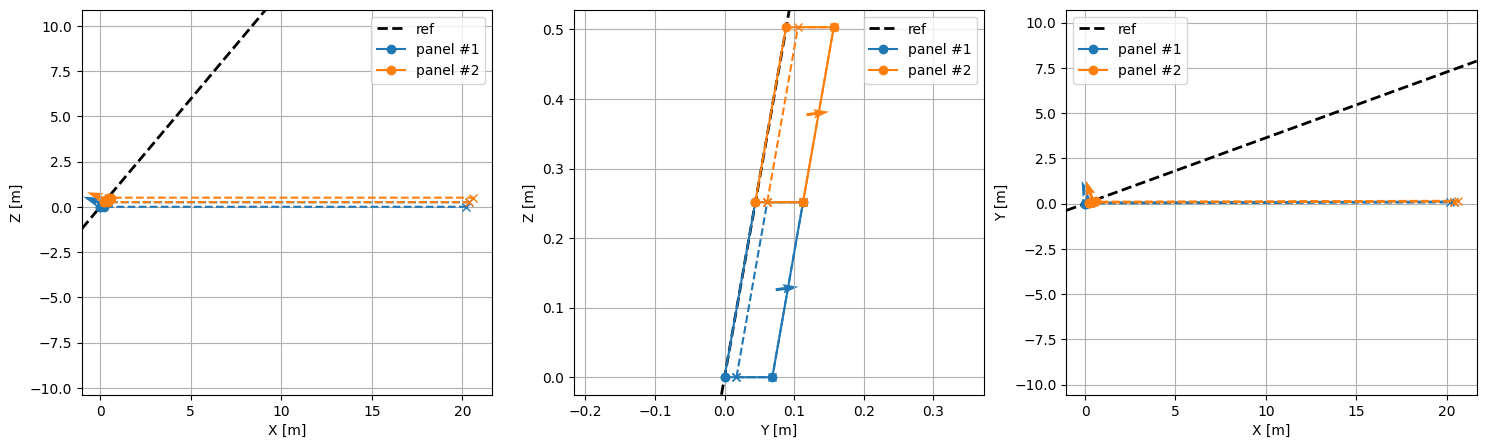

In [7]:
%matplotlib inline
## 2D PLOT

fig_test = plt.figure(figsize=(18, 5))
ax1 = fig_test.add_subplot(1, 3, 1)
ax2 = fig_test.add_subplot(1, 3, 2)
ax3 = fig_test.add_subplot(1, 3, 3)

for i, panel in enumerate(vlm.panels):
    pnt    = copy.copy(panel.pnt)
    ctr    = copy.copy(panel.ctr)
    normal = copy.copy(panel.normal)
    vrt    = copy.copy(panel.vrt)
    # Close the polygon shape
    pnt.append(pnt[0])
    pnt_plt = np.array(pnt)
    vrt.append(vrt[0])
    vrt_plt = np.array(vrt)

    if i == 0:
        # Store root panel vertices
        pnt_root = pnt

        # Plot reference direction
        ax1.axline(pnt_plt[0, :2:],  slope=np.tan(np.deg2rad(90-LAMBDA)), c='k', lw=2, ls='--', label="ref")
        ax2.axline(pnt_plt[0, 1::],  slope=np.tan(np.deg2rad(90-GAMMA)),  c='k', lw=2, ls='--', label="ref")
        ax3.axline(pnt_plt[0, ::-2], slope=np.tan(np.deg2rad(THETA)),     c='k', lw=2, ls='--', label="ref")
    elif i == (N - 1):
        # Store tip panel vertices
        pnt_tip = pnt

    # Select plotting color
    clr = ax1._get_lines.get_next_color()

    # Plot lattice
    # lateral view
    ax1.plot(pnt_plt[:, 0], pnt_plt[:, 2], '-o',     color=clr, label=f"panel #{i+1}")
    ax1.plot(vrt_plt[:, 0], vrt_plt[:, 2], '--x',    color=clr)
    ax1.quiver(ctr[0], ctr[2], normal[0], normal[2], color=clr)
    # frontal view
    ax2.plot(pnt_plt[:, 1], pnt_plt[:, 2], '-o',     color=clr, label=f"panel #{i+1}")
    ax2.plot(vrt_plt[:, 1], vrt_plt[:, 2], '--x',    color=clr)
    ax2.quiver(ctr[1], ctr[2], normal[1], normal[2], color=clr)
    # top view
    ax3.plot(pnt_plt[:, 0], pnt_plt[:, 1], '-o',     color=clr, label=f"panel #{i+1}")
    ax3.plot(vrt_plt[:, 0], vrt_plt[:, 1], '--x',    color=clr)
    ax3.quiver(ctr[0], ctr[1], normal[0], normal[1], color=clr)

ax1.set_xlabel("X [m]")
ax1.set_ylabel("Z [m]")
ax1.axis('equal')
ax1.legend()
ax1.grid(True)
ax2.set_xlabel("Y [m]")
ax2.set_ylabel("Z [m]")
ax2.axis('equal')
ax2.legend()
ax2.grid(True)
ax3.set_xlabel("X [m]")
ax3.set_ylabel("Y [m]")
ax3.axis('equal')
ax3.legend()
ax3.grid(True)

# Compute wing attitude
dir_chord = normalize(pnt_root[3] - pnt_root[0])    # chordwise direction
dir_span = normalize(pnt_tip[1] - pnt_root[0])      # spanwise direction

print("Computed wing geometry:")
print(f"    - Incidence angle = {np.rad2deg(np.atan2(dir_chord[1], dir_chord[0])):.2f}°")
print(f"    - Dihedral angle = {np.rad2deg(np.atan2(dir_span[1], dir_span[2])):.2f}°")
print(f"    - Sweep angle = {np.rad2deg(np.atan2(dir_span[0], dir_span[2])):.1f}°")

del pnt, pnt_plt, ctr, normal, vrt, vrt_plt

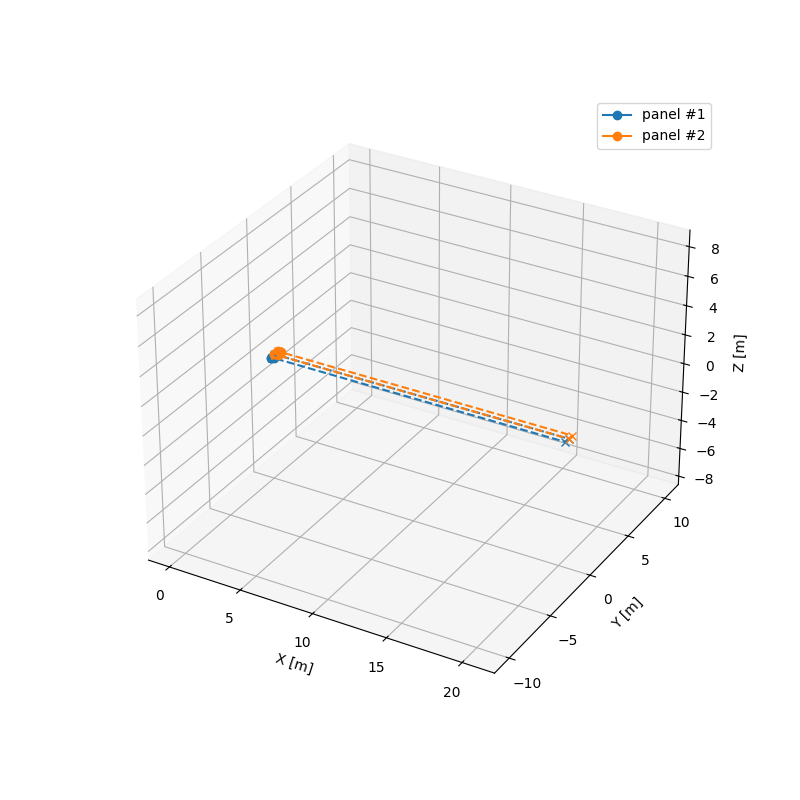

In [8]:
%matplotlib widget
## 3D PLOT

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(1, 1, 1, projection='3d')

for i, panel in enumerate(vlm.panels):
    pnt    = copy.copy(panel.pnt)
    ctr    = copy.copy(panel.ctr)
    normal = copy.copy(panel.normal)
    vrt    = copy.copy(panel.vrt)
    # Close the polygon shape
    pnt.append(pnt[0])
    pnt_plt = np.array(pnt)
    vrt.append(vrt[0])
    vrt_plt = np.array(vrt)

    # Select plotting color
    clr = ax._get_lines.get_next_color()

    # Plot lattice
    ax.plot(pnt_plt[:, 0], pnt_plt[:, 1], pnt_plt[:, 2], '-o',     color=clr, label=f"panel #{i+1}")
    ax.plot(vrt_plt[:, 0], vrt_plt[:, 1], vrt_plt[:, 2], '--x',    color=clr)
    ax.quiver(ctr[0], ctr[1], ctr[2], normal[0], normal[1], normal[2], color=clr, length=(0.1 * B))

ax.set_xlabel("X [m]")
ax.set_ylabel("Y [m]")
ax.set_zlabel("Z [m]")
ax.axis('equal')
ax.legend()
ax.grid(True)

del pnt, pnt_plt, ctr, normal, vrt, vrt_plt

In [9]:
# from matplotlib.ticker import MultipleLocator
# %matplotlib widget

# def read_avl(filename):
#     """ 
#     Read a xflr5 wing file and return sections
#     Input:
#     -> filename the filename
#     """
#     sections = []
#     with open(filename, 'r') as f:
#         lines = f.readlines()
#     i = 0
#     while i < len(lines):
#         line = lines[i].strip()
#         if line.startswith("SECTION"):
#             vals = lines[i+1].split()
#             x, y, z, chord, twist = map(float, vals[:5])

#             sections.append({
#                 "x": x,
#                 "y": y,
#                 "z": z,
#                 "chord": chord,
#                 "twist": twist
#             })
#             i += 2
#         else:
#             i += 1
#     return sections

# def build_panels(sections, n_span=10, n_chord=N):
#     """ 
#     From the sections of read_avl it build panels similar to the vlm, with the corner points
#     Input:
#     -> sections, obtained with read_avl
#     -> n_span the number of spanwise panels
#     -> n_chord the number of chordwise panels
#     """
#     panels = []
#     for i in range(len(sections)-1):
#         s1 = sections[i]
#         s2 = sections[i+1]
#         for j in range(n_span):
#             eta1 = j / n_span
#             eta2 = (j+1) / n_span
#             #spanwise interpolation
#             def interp(s, t):
#                 return (1-t)*s1[s] + t*s2[s]
#             y1, y2 = interp("y", eta1), interp("y", eta2)
#             x1, x2 = interp("x", eta1), interp("x", eta2)
#             z1, z2 = interp("z", eta1), interp("z", eta2)
#             c1, c2 = interp("chord", eta1), interp("chord", eta2)
#             for k in range(n_chord):
#                 xsi1 = k / n_chord
#                 xsi2 = (k+1) / n_chord
#                 # panel corner points
#                 p1 = [x1 + xsi1*c1, y1, z1]
#                 p2 = [x2 + xsi1*c2, y2, z2]
#                 p3 = [x2 + xsi2*c2, y2, z2]
#                 p4 = [x1 + xsi2*c1, y1, z1]
#                 panels.append(np.array([p1, p2, p3, p4]))
#     return panels

    
# fig = plt.figure(figsize=(19, 5))
# ax = fig.add_subplot(111, projection='3d')

# # --- AVL ---
# sections = read_avl("docs/xflr5_wing_30_15.avl")
# panels_avl = build_panels(sections)
# for i, p in enumerate(panels_avl):
#     poly = np.vstack((p, p[0]))
#     ax.plot(poly[:,1], poly[:,0], poly[:,2],
#             color='red',
#             label='XFLR5' if i == 0 else None)

# # --- VLM ---
# for i, panel in enumerate(vlm.panels):
#     p = np.array(panel.pnt)
#     p = np.vstack((p, p[0]))
#     ax.plot(p[:,2], p[:,0], p[:,1],
#             color='blue',
#             label='VLM' if i == 0 else None)

# ax.view_init(elev=20, azim=-120)
# ax.set_xlim(0, 0.5)
# ax.set_zlim(0, 0.2)
# ax.set_ylim(0, 0.5)
# ax.set_box_aspect([0.5,0.5,0.2])
# ax.legend()
# ax.set_xlabel("z")
# ax.set_ylabel("x")
# ax.set_zlabel("y")
# ax.zaxis.set_major_locator(MultipleLocator(0.1))